# Detecção de deepfakes em imagens faciais — EDA e modelo baseline

**Projeto Integrador · Marco 1 (Seções 3 e 4)**

Este notebook reproduz, passo a passo, a análise exploratória (EDA) e o treinamento do modelo baseline descritos no documento do Marco 1. Cada etapa traz uma explicação do *porquê* antes do código.

**Pergunta central da EDA:** os dados permitem que um classificador aprenda a **manipulação** do rosto, ou ele pode acertar apenas pela **origem** da imagem (CelebA × FaceForensics++)?

**Roteiro**

1. Dados brutos: CelebA e FaceForensics++ (FF++)
2. Como reais e fakes do FF++ são pareados
3. Detecção, recorte e atributos de cada imagem
4. Extração em lote → tabela `manifest.csv`
5. Qualidade dos dados
6. Visualização 1 — composição e balanceamento
7. Visualização 2 — viés de origem
8. Visualização 3 — sinais de manipulação pareados
9. Modelo baseline (regressão logística)
10. Controle do viés de origem
11. Conclusões

**Estrutura de pastas esperada**

```
PI/
├── Celeba/                       # CelebA (Kaggle): img_align_celeba/ + 4 CSVs de anotação
├── FaceForensics/                # FF++ c23 baixado pelo script oficial
│   ├── original_sequences/youtube/c23/videos/     (1.000 vídeos reais)
│   ├── manipulated_sequences/FaceSwap/c23/videos/ (1.000 vídeos fake)
│   ├── manipulated_sequences/FaceSwap/masks/videos/
│   └── splits/{train,val,test}.json
├── eda/                          # este notebook + scripts
│   ├── extract_features.py       # detecção, recorte e atributos
│   ├── extract_cnn_features.py   # embeddings ResNet-18
│   └── baselines.py              # treino e avaliação da regressão logística
└── derived/                      # saídas: manifest.csv, espectros, recortes, embeddings
```

**Ambiente:** Python 3.12 com `numpy`, `pandas`, `scipy`, `matplotlib`, `opencv-python-headless`, `pillow`, `torch`, `torchvision`, `facenet-pytorch` (instalado com `--no-deps`) e `scikit-learn`.

In [1]:
import os, sys, json, subprocess, time
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, wilcoxon

# Caminhos (o notebook fica em PI/eda/)
EDA = Path.cwd()
PI = EDA.parent
CEL = PI / "Celeba"
FF = PI / "FaceForensics"
V_O = FF / "original_sequences/youtube/c23/videos"
V_F = FF / "manipulated_sequences/FaceSwap/c23/videos"
V_M = FF / "manipulated_sequences/FaceSwap/masks/videos"
D = PI / "derived"
sys.path.insert(0, str(EDA))

# Etapas pesadas: deixe False para carregar os resultados já salvos em derived/
RUN_EXTRACTION = False   # ~20 min em 8 núcleos: frames, detecção, recortes e atributos
RUN_CNN = False          # ~10 min em CPU: embeddings ResNet-18 dos 30 mil recortes

SEED = 42
COL = {"celeba_real": "#56B4E9", "ffpp_real": "#0072B2", "ffpp_faceswap": "#D55E00"}
LAB = {"celeba_real": "CelebA (real)", "ffpp_real": "FF++ original (real)", "ffpp_faceswap": "FF++ FaceSwap (fake)"}
ORDER = ["celeba_real", "ffpp_real", "ffpp_faceswap"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
def letter(ax, s):
    ax.text(-0.12, 1.06, s, transform=ax.transAxes, fontsize=12, fontweight="bold", va="bottom")
for p in [CEL, V_O, V_F, V_M, FF / "splits"]:
    assert p.exists(), f"faltando: {p}"
print("OK:", PI)

OK: /Users/iancarlos/Repositories/Barao/8Semestre/PI


## 1. Dados brutos

### 1.1 CelebA

O CelebA traz 202.599 fotos de celebridades já **alinhadas e recortadas** (178×218 px, JPEG), com quatro arquivos de anotação: 40 atributos binários (−1/1), bounding box, 5 landmarks e a partição oficial treino/validação/teste. Verificamos tamanho, valores faltantes e a prevalência de alguns atributos — esta última importa para a **dimensão ética** (o detector pode funcionar pior para grupos sub-representados).

In [2]:
attr = pd.read_csv(CEL / "list_attr_celeba.csv")
part = pd.read_csv(CEL / "list_eval_partition.csv")
bbox = pd.read_csv(CEL / "list_bbox_celeba.csv")
lmk = pd.read_csv(CEL / "list_landmarks_align_celeba.csv")
n_files = len(os.listdir(CEL / "img_align_celeba/img_align_celeba"))
print("imagens:", len(attr), "| arquivos no disco:", n_files, "| atributos:", attr.shape[1] - 1)
print("valores faltantes nas 4 tabelas:", int(sum(t.isna().sum().sum() for t in [attr, part, bbox, lmk])))
print("valores possíveis dos atributos:", sorted(pd.unique(attr.iloc[:, 1:].values.ravel())))
print("partição (0=treino, 1=val, 2=teste):", part.partition.value_counts().sort_index().to_dict())
prev = (attr.iloc[:, 1:] == 1).mean()
prev[["Male", "Young", "Pale_Skin", "Eyeglasses", "Blurry", "Wearing_Hat"]].mul(100).round(1).to_frame("% das imagens")

imagens: 202599 | arquivos no disco: 202599 | atributos: 40
valores faltantes nas 4 tabelas: 0
valores possíveis dos atributos: [np.int64(-1), np.int64(1)]
partição (0=treino, 1=val, 2=teste): {0: 162770, 1: 19867, 2: 19962}


,% das imagens
Male,41.7
Young,77.4
Pale_Skin,4.3
Eyeglasses,6.5
Blurry,5.1
Wearing_Hat,4.8


### 1.2 FaceForensics++ (c23)

O FF++ tem 1.000 vídeos originais do YouTube e, para cada método de manipulação, 1.000 vídeos fake. Usamos o método **FaceSwap** na compressão **c23** (H.264, CRF 23). Os vídeos fake se chamam `A_B.mp4`: a cena vem do vídeo **A** (alvo) e o rosto vem do vídeo **B** (fonte).

A divisão oficial (`splits/*.json`) lista **pares** `[A, B]`; os dois originais e os dois fakes (`A_B` e `B_A`) de um par ficam sempre no mesmo split. Verificamos a seguir se algum vídeo aparece em mais de um split (vazamento).

In [3]:
vid_csv = D / "ffpp_videos.csv"
if vid_csv.exists():
    vids = pd.read_csv(vid_csv)
else:
    rows = []
    for grp, d in [("ffpp_real", V_O), ("ffpp_faceswap", V_F)]:
        for f in sorted(d.glob("*.mp4")):
            c = cv2.VideoCapture(str(f))
            rows.append(dict(group=grp, video=f.stem, frames=int(c.get(cv2.CAP_PROP_FRAME_COUNT)),
                             w=int(c.get(cv2.CAP_PROP_FRAME_WIDTH)), h=int(c.get(cv2.CAP_PROP_FRAME_HEIGHT)),
                             fps=c.get(cv2.CAP_PROP_FPS), mb=f.stat().st_size / 1e6))
            c.release()
    vids = pd.DataFrame(rows); D.mkdir(exist_ok=True); vids.to_csv(vid_csv, index=False)

display(vids.groupby("group").agg(videos=("video", "size"), frames_total=("frames", "sum"), frames_mediana=("frames", "median"),
                                  fps=("fps", "median"), GB=("mb", lambda s: round(s.sum() / 1e3, 2))))
vids["resolucao"] = np.select([vids.h >= 1000, vids.h >= 700], ["1080p", "720p"], "480p")
display(vids.groupby(["resolucao", "group"]).size().unstack())

splits = {s: json.load(open(FF / "splits" / f"{s}.json")) for s in ["train", "val", "test"]}
ids = {s: {v for p in P for v in p} for s, P in splits.items()}
print("pares por split:", {s: len(P) for s, P in splits.items()}, "| vídeos originais por split:", {s: len(v) for s, v in ids.items()})
print("sobreposição treino∩val, treino∩teste, val∩teste:", len(ids["train"] & ids["val"]), len(ids["train"] & ids["test"]), len(ids["val"] & ids["test"]))

pares por split: {'train': 360, 'val': 70, 'test': 70} | vídeos originais por split: {'train': 720, 'val': 140, 'test': 140}
sobreposição treino∩val, treino∩teste, val∩teste: 0 0 0


,videos,frames_total,frames_mediana,fps,GB
group,,,,,
ffpp_faceswap,1000,406140,375.0,25.0,1.64
ffpp_real,1000,509128,457.5,25.0,1.94


group,ffpp_faceswap,ffpp_real
resolucao,,
1080p,126,126
480p,536,536
720p,338,338


## 2. Como reais e fakes do FF++ são pareados

Antes de extrair frames, confirmamos duas suposições sobre os arquivos, porque todo o desenho da análise depende delas:

1. **`A_B` usa a cena de A.** Se for verdade, o frame *i* de `A_B` deve ser quase idêntico ao frame *i* de A fora do rosto (diferença média pequena) e muito diferente do frame *i* de B.
2. **A máscara está alinhada ao fake.** Os vídeos de máscara guardam os pixels da face trocada sobre fundo preto; binarizamos com `max(canais) > 10`.

Se as duas se confirmam, podemos comparar **o mesmo frame** real e fake — um experimento controlado em que só a face muda.

frames: fake=303, original A=396, original B=303  → o fake é truncado ao vídeo mais curto
|fake − A| médio = 2.0   |fake − B| médio = 97.2
máscara cobre 3.9% do frame


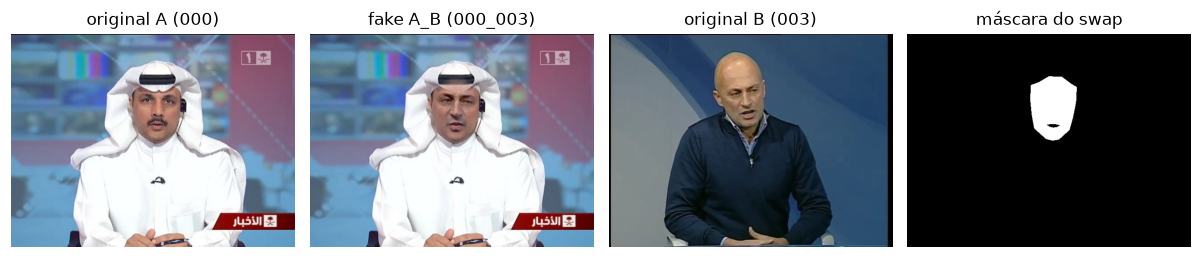

In [4]:
def read_frames(path, idxs):
    cap = cv2.VideoCapture(str(path)); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); out, i = {}, 0
    while i <= max(idxs):
        if not cap.grab(): break
        if i in idxs: out[i] = cap.retrieve()[1]
        i += 1
    cap.release(); return n, out

pair, k = "000_003", 50
a, b = pair.split("_")
n_f, F = read_frames(V_F / f"{pair}.mp4", [k]); n_a, A = read_frames(V_O / f"{a}.mp4", [k])
n_b, Bv = read_frames(V_O / f"{b}.mp4", [k]); _, M = read_frames(V_M / f"{pair}.mp4", [k])
fake, orig, srcb, mask = F[k], A[k], Bv[k], M[k].max(axis=2) > 10
print(f"frames: fake={n_f}, original A={n_a}, original B={n_b}  → o fake é truncado ao vídeo mais curto")
print(f"|fake − A| médio = {np.abs(fake.astype(float) - orig).mean():.1f}   |fake − B| médio = {np.abs(fake.astype(float) - srcb).mean():.1f}")
print(f"máscara cobre {mask.mean()*100:.1f}% do frame")

fig, axs = plt.subplots(1, 4, figsize=(11, 2.4))
for ax, im, t in zip(axs, [orig, fake, srcb, mask], [f"original A ({a})", f"fake A_B ({pair})", f"original B ({b})", "máscara do swap"]):
    ax.imshow(im if im.ndim == 2 else im[..., ::-1], cmap="gray"); ax.set_title(t); ax.axis("off")
fig.tight_layout()

**Resultado:** o fake difere pouco de A (≈2 níveis de cinza) e muito de B (≈97), então `A_B` = cena de A com o rosto de B. Como o fake é truncado ao vídeo mais curto do par, os frames são amostrados **dentro do comprimento do fake** e os mesmos índices são lidos do original e da máscara.

## 3. Detecção, recorte e atributos de cada imagem

Todas as imagens — CelebA e FF++ — passam pelo **mesmo** pré-processamento, para que as diferenças entre grupos não venham do código:

1. **Detecção** com MTCNN (`facenet-pytorch`); se houver mais de um rosto, fica o maior.
2. **Recorte quadrado** com margem de 1,3× o lado da caixa, deslocado para caber na imagem, e redimensionado para 256×256 px.
3. **Atributos** (calculados no recorte, exceto o artefato de bloco):

| Atributo | Como é calculado | O que captura |
|---|---|---|
| `face_px` | √(largura × altura) da caixa, em px da imagem original | resolução do rosto |
| `det_prob` | confiança do MTCNN | qualidade da detecção |
| `sharpness` | variância do Laplaciano do recorte em cinza | nitidez / desfoque |
| `hf_ratio` | energia do espectro 2D com frequência > 0,25 ciclo/px ÷ energia total (sem DC) | detalhe fino, artefatos de blending/reamostragem |
| `blockiness` | \|diferença\| entre pixels vizinhos **nas fronteiras** da grade 8×8 ÷ \|diferença\| fora delas (na imagem original) | artefato de compressão por blocos (≈1 = sem blocos) |
| `brightness`, `saturation` | médias de V e S no espaço HSV | iluminação e cor |
| `eye_dist_rel` | distância entre os olhos ÷ largura da caixa | geometria do rosto |
| espectro radial | média da potência por anel de frequência (128 faixas) | assinatura de frequência completa |
| `mask_frac`, `tex_logratio`, `color_dist` | só FF++: área da máscara; log(\|Laplaciano\| dentro ÷ anel fora da máscara); distância de cor Lab dentro × fora | inconsistência entre face e entorno |

As variáveis de máscara são calculadas também para o **original** usando a máscara do seu fake (a geometria é a mesma), o que permite a comparação pareada. Elas **não** podem ser usadas pelo classificador, pois a máscara não existe na inferência.

Abaixo, as funções do script aplicadas ao frame de exemplo.

,original,fake
det_prob,0.9998,0.9998
face_px,117.2720,115.9771
sharpness,169.3054,178.0606
hf_ratio,0.0085,0.0144
blockiness,0.9040,0.9167
brightness,179.3081,174.5464
saturation,45.5379,45.2706
eye_dist_rel,0.4656,0.4349


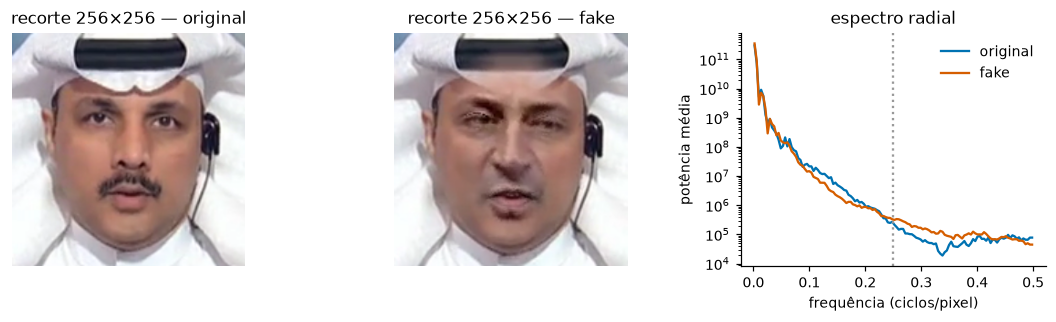

In [5]:
import extract_features as EF
EF._init()   # carrega o MTCNN
ex = {}
for name, img in [("original", orig), ("fake", fake)]:
    row, spec, box = EF.image_features(img)
    ex[name] = (row, spec, box)
keys = ["det_prob", "face_px", "sharpness", "hf_ratio", "blockiness", "brightness", "saturation", "eye_dist_rel"]
display(pd.DataFrame({n: {k_: round(v[0][k_], 4) for k_ in keys} for n, v in ex.items()}))

fig, axs = plt.subplots(1, 3, figsize=(10, 3))
for ax, (n, (row, spec, (x0, y0, x1, y1))), src in zip(axs[:2], ex.items(), [orig, fake]):
    ax.imshow(cv2.resize(src[y0:y1, x0:x1], (256, 256))[..., ::-1]); ax.set_title(f"recorte 256×256 — {n}"); ax.axis("off")
freq = (np.arange(EF.NBINS) + 0.5) / EF.NBINS * 0.5
for n, c in [("original", COL["ffpp_real"]), ("fake", COL["ffpp_faceswap"])]:
    axs[2].semilogy(freq, ex[n][1], color=c, label=n)
axs[2].axvline(0.25, color="0.6", ls=":"); axs[2].set_xlabel("frequência (ciclos/pixel)"); axs[2].set_ylabel("potência média")
axs[2].set_title("espectro radial"); axs[2].legend(frameon=False)
fig.tight_layout()

## 4. Extração em lote → `manifest.csv`

**Amostragem**

- **FF++:** para cada um dos 1.000 vídeos FaceSwap `A_B`, 10 frames nas posições (j + 0,5)/10 do comprimento do fake (j = 0…9); os mesmos índices são lidos do original A e da máscara. Resultado: 10.000 frames reais + 10.000 fakes, pareados.
- **CelebA:** 10.000 imagens sorteadas com semente 42, proporcionalmente a cada partição oficial.

Amostrar poucos frames por vídeo é intencional: frames vizinhos são quase idênticos, e a **unidade independente é o vídeo**, não o frame.

O script roda em paralelo (8 processos) e grava `derived/manifest.csv` (uma linha por imagem), `derived/manifest_spectra.npz` (espectro radial de cada linha) e os recortes em `derived/crops/`.

In [6]:
if RUN_EXTRACTION:
    t0 = time.time()
    subprocess.run([sys.executable, "extract_features.py", "--frames", "10", "--celeba_n", "10000", "--workers", "8"], cwd=EDA, check=True)
    print(f"extração concluída em {time.time() - t0:.0f}s")

man = pd.read_csv(D / "manifest.csv", low_memory=False)
S = np.load(D / "manifest_spectra.npz")["spectra"]
assert len(man) == len(S) == 30000
man["row"] = np.arange(len(man))
print(man.shape)
man[["group", "video_id", "split", "frame_idx", "detected", "face_px", "sharpness", "hf_ratio", "blockiness"]].sample(5, random_state=0)

(30000, 44)


,group,video_id,split,frame_idx,detected,face_px,sharpness,hf_ratio,blockiness
8225,ffpp_real,506,train,367.0,1,120.948777,27.253054,0.004749,0.985365
10794,ffpp_faceswap,699_734,train,235.0,1,107.714374,89.664779,0.008015,0.960700
9163,ffpp_real,830,train,111.0,1,119.699310,112.015157,0.005550,1.035911
26591,celeba_real,157610.jpg,train,NaN,1,105.342457,560.031789,0.035863,1.088464
6631,ffpp_faceswap,986_994,train,47.0,1,113.153078,55.733561,0.013973,1.057388


## 5. Qualidade dos dados

Verificamos, por grupo: falhas de decodificação, falhas de detecção, frames com mais de um rosto, valores faltantes por variável e a contagem por split. Também checamos se o rosto escolhido (o maior) é de fato o rosto manipulado: sorteamos 400 frames fake e testamos se o centro da máscara cai dentro da caixa detectada.

In [7]:
q = man.groupby("group").agg(imagens=("video_id", "size"), unidades=("video_id", "nunique"), decodificou=("decode_ok", "mean"),
                             rosto_detectado=("detected", "mean"), mais_de_um_rosto=("n_faces", lambda s: (s > 1).mean()))
display(q.round(4))
feat = ["det_prob", "face_px", "sharpness", "hf_ratio", "blockiness", "mask_frac", "tex_logratio", "color_dist", "jpeg_q"]
display(man[feat].isna().groupby(man.group).mean().round(3).T.rename_axis("fração faltante"))
display(man.groupby(["group", "split"]).size().unstack()[["train", "val", "test"]])

ff = man[man.source == "FaceForensics++"]
sub = ff[(ff.group == "ffpp_faceswap") & (ff.detected == 1)].sample(400, random_state=0)
inside = []
for _, r in sub.iterrows():
    _, Mk = read_frames(V_M / f"{r.video_id}.mp4", [int(r.frame_idx)])
    ys, xs = np.nonzero(Mk[int(r.frame_idx)].max(axis=2) > 10)
    inside.append(np.nan if len(xs) == 0 else float(r.bx0 <= xs.mean() <= r.bx1 and r.by0 <= ys.mean() <= r.by1))
inside = np.array(inside)
print(f"centro da máscara dentro do rosto escolhido: {np.nanmean(inside)*100:.1f}% (frames com >1 rosto: {np.nanmean(inside[(sub.n_faces > 1).values])*100:.1f}%)")

centro da máscara dentro do rosto escolhido: 99.2% (frames com >1 rosto: 95.4%)


,imagens,unidades,decodificou,rosto_detectado,mais_de_um_rosto
group,,,,,
celeba_real,10000,10000,1.0,0.9981,0.0167
ffpp_faceswap,10000,1000,1.0,0.9999,0.1655
ffpp_real,10000,1000,1.0,0.9999,0.1609


group,celeba_real,ffpp_faceswap,ffpp_real
fração faltante,,,
det_prob,0.002,0.000,0.000
face_px,0.002,0.000,0.000
sharpness,0.002,0.000,0.000
hf_ratio,0.002,0.000,0.000
blockiness,0.002,0.000,0.000
mask_frac,1.000,0.000,0.000
tex_logratio,1.000,0.001,0.001
color_dist,1.000,0.001,0.001
jpeg_q,0.000,1.000,1.000


split,train,val,test
group,,,
celeba_real,8034,981,985
ffpp_faceswap,7200,1400,1400
ffpp_real,7200,1400,1400


**Leitura:** nenhum arquivo falhou na decodificação; o detector falhou em 0,19% do CelebA e 0,01% do FF++. Os ~16% de frames do FF++ com mais de um rosto não comprometem a análise, pois o rosto escolhido contém a região manipulada em ~99% dos casos. As variáveis de máscara faltam no CelebA por construção (não há máscara), e `jpeg_q` só existe para o CelebA (o FF++ é H.264).

## 6. Visualização 1 — composição e balanceamento

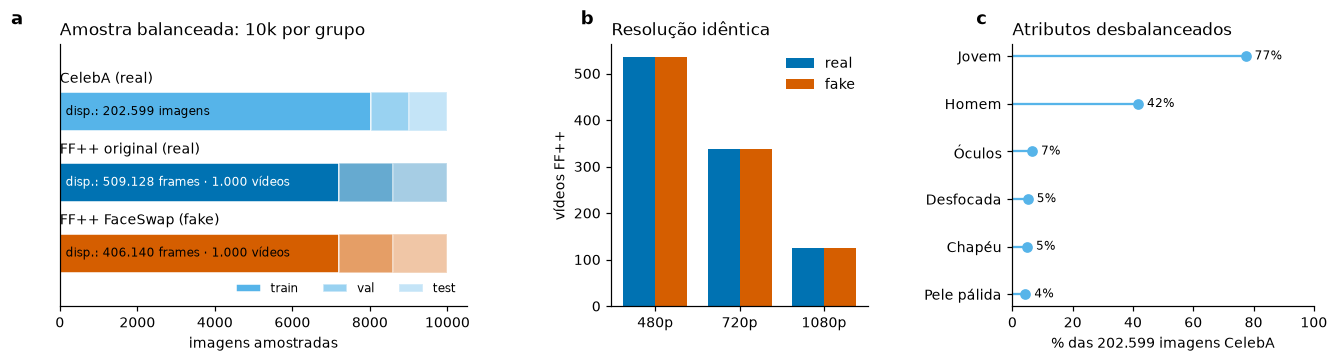

In [8]:
cnt = man.groupby(["group", "split"]).size().unstack()[["train", "val", "test"]].loc[ORDER]
avail = {"celeba_real": "202.599 imagens", "ffpp_real": "509.128 frames · 1.000 vídeos", "ffpp_faceswap": "406.140 frames · 1.000 vídeos"}
alphas = {"train": 1.0, "val": 0.6, "test": 0.35}
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1.35, 0.85, 1.0], wspace=0.45))
ax = axs[0]; y = np.arange(3)[::-1]; left = np.zeros(3)
for s in ["train", "val", "test"]:
    ax.barh(y, cnt[s].values, left=left, color=[COL[g] for g in ORDER], alpha=alphas[s], edgecolor="white", height=0.55, label=s)
    left += cnt[s].values
for yi, g in zip(y, ORDER):
    ax.text(0, yi + 0.36, LAB[g], va="bottom"); ax.text(150, yi, "disp.: " + avail[g], va="center", fontsize=8, color="white" if g == "ffpp_real" else "black")
ax.set_yticks([]); ax.set_xlabel("imagens amostradas"); ax.set_ylim(-0.75, 2.95); ax.legend(frameon=False, ncol=3, loc="lower right", fontsize=8)
ax.set_title("Amostra balanceada: 10k por grupo", loc="left"); letter(ax, "a")
ax = axs[1]; res = vids.groupby(["resolucao", "group"]).size().unstack().loc[["480p", "720p", "1080p"]]
x = np.arange(3)
for j, g in enumerate(["ffpp_real", "ffpp_faceswap"]):
    ax.bar(x + (j - 0.5) * 0.38, res[g].values, 0.38, color=COL[g], label=["real", "fake"][j])
ax.set_xticks(x, res.index); ax.set_ylabel("vídeos FF++"); ax.legend(frameon=False); ax.set_title("Resolução idêntica", loc="left"); letter(ax, "b")
ax = axs[2]; sel = {"Male": "Homem", "Young": "Jovem", "Pale_Skin": "Pele pálida", "Eyeglasses": "Óculos", "Blurry": "Desfocada", "Wearing_Hat": "Chapéu"}
pv = prev[list(sel)].sort_values()
ax.hlines(range(len(pv)), 0, pv * 100, color=COL["celeba_real"], lw=1.5); ax.plot(pv * 100, range(len(pv)), "o", color=COL["celeba_real"])
for i, v in enumerate(pv): ax.text(v * 100 + 3, i, f"{v*100:.0f}%", va="center", fontsize=8)
ax.set_yticks(range(len(pv)), [sel[k] for k in pv.index]); ax.set_xlim(0, 100); ax.set_xlabel("% das 202.599 imagens CelebA")
ax.set_title("Atributos desbalanceados", loc="left"); letter(ax, "c")
fig.subplots_adjust(left=0.03, right=0.98, bottom=0.18)

**Interpretação:** a amostra é balanceada e segue os splits oficiais; como cada fake herda a cena do seu original, real e fake do FF++ têm a mesma distribuição de resolução. O CelebA é desbalanceado em atributos demográficos (77% jovens, 4% pele pálida) — uma limitação ética, pois não há como garantir desempenho igual para todos os grupos. Em volume, as classes parecem grandes, mas a classe fake tem só **1.000 vídeos independentes**.

## 7. Visualização 2 — viés de origem

Para quantificar o quanto **uma única** característica separa dois grupos, usamos a **AUC** (área sob a curva ROC), calculada pela estatística U de Mann-Whitney: AUC = U / (n₁·n₂). Como a direção não importa aqui, reportamos max(AUC, 1 − AUC): 0,5 = acaso, 1 = separação perfeita. Comparamos dois cenários:

- **CelebA (real) × FaceSwap (fake):** o que aconteceria se usássemos o CelebA como classe real;
- **FF++ original × FaceSwap:** reais e fakes da mesma origem.

,CelebA × fake,FF++ real × fake
blockiness,0.954,0.566
face_px,0.899,0.501
sharpness,0.758,0.518
hf_ratio,0.737,0.665
det_prob,0.546,0.506
eye_dist_rel,0.530,0.511
brightness,0.518,0.502
saturation,0.515,0.502


,face_px,sharpness,hf_ratio,blockiness
group,,,,
celeba_real,98.389,165.443,0.016,1.180
ffpp_real,160.837,78.997,0.006,1.032
ffpp_faceswap,160.135,82.449,0.010,1.018


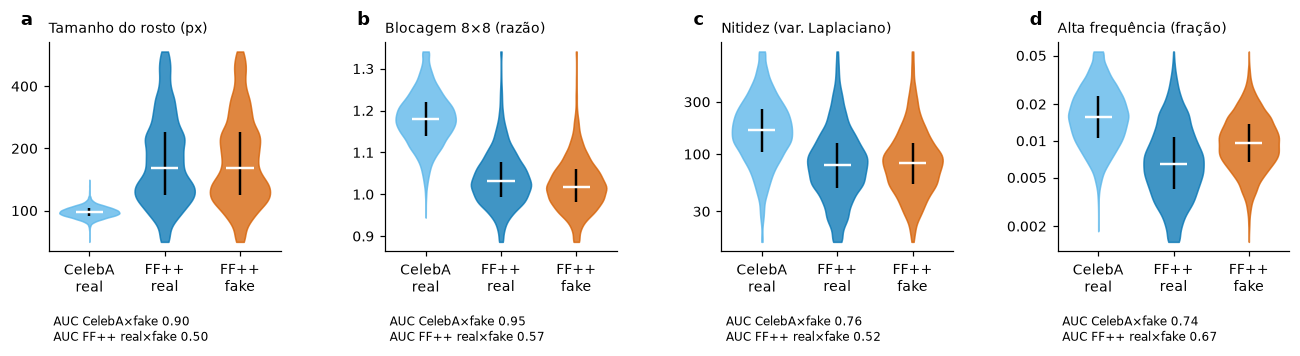

In [9]:
ok = man[man.detected == 1]
def sep_auc(pos, neg):
    pos, neg = pos.dropna(), neg.dropna(); a = mannwhitneyu(pos, neg).statistic / (len(pos) * len(neg)); return max(a, 1 - a)
g = {k: v for k, v in ok.groupby("group")}
feats = ["face_px", "sharpness", "hf_ratio", "blockiness", "brightness", "saturation", "det_prob", "eye_dist_rel"]
aucs = pd.DataFrame({f: {"CelebA × fake": sep_auc(g["ffpp_faceswap"][f], g["celeba_real"][f]),
                         "FF++ real × fake": sep_auc(g["ffpp_faceswap"][f], g["ffpp_real"][f])} for f in feats}).T.round(3)
display(aucs.sort_values("CelebA × fake", ascending=False))
display(ok.groupby("group")[["face_px", "sharpness", "hf_ratio", "blockiness"]].median().round(3).loc[ORDER])

F2 = [("face_px", "Tamanho do rosto (px)", True, [50, 100, 200, 400]), ("blockiness", "Blocagem 8×8 (razão)", False, None),
      ("sharpness", "Nitidez (var. Laplaciano)", True, [30, 100, 300, 1000]), ("hf_ratio", "Alta frequência (fração)", True, [0.002, 0.005, 0.01, 0.02, 0.05])]
fig, axs = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (f, lab, lg, tk), l in zip(axs, F2, "abcd"):
    dd = [ok.loc[ok.group == gr, f].dropna().values for gr in ORDER]
    dd = [np.log10(d) if lg else d for d in dd]
    lo, hi = np.percentile(np.concatenate(dd), [0.5, 99.5]); dd = [np.clip(d, lo, hi) for d in dd]
    vp = ax.violinplot(dd, positions=range(3), widths=0.8, showextrema=False)
    for bdy, gr in zip(vp["bodies"], ORDER): bdy.set_facecolor(COL[gr]); bdy.set_edgecolor(COL[gr]); bdy.set_alpha(0.75)
    for i, d in enumerate(dd):
        q1, md_, q3 = np.percentile(d, [25, 50, 75]); ax.vlines(i, q1, q3, color="k", lw=1.6); ax.hlines(md_, i - 0.18, i + 0.18, color="white", lw=1.6)
    if lg:
        tk = [t for t in tk if lo <= np.log10(t) <= hi]; ax.set_yticks(np.log10(tk), [f"{t:g}" for t in tk])
    ax.set_xticks(range(3), ["CelebA\nreal", "FF++\nreal", "FF++\nfake"]); ax.set_title(lab, loc="left", fontsize=9)
    ax.text(0.02, -0.3, f"AUC CelebA×fake {aucs.loc[f, 'CelebA × fake']:.2f}\nAUC FF++ real×fake {aucs.loc[f, 'FF++ real × fake']:.2f}", transform=ax.transAxes, fontsize=8, va="top")
    letter(ax, l)
fig.subplots_adjust(left=0.05, right=0.99, top=0.88, bottom=0.32, wspace=0.45)

**Interpretação:** sozinho, o artefato de bloco do JPEG separa CelebA dos fakes com AUC ≈ 0,95, e o tamanho do rosto com ≈ 0,90; as mesmas medidas quase não distinguem real de fake dentro do FF++ (0,50–0,57). Um classificador treinado com CelebA como real aprenderia a **origem** da imagem (compressão, resolução), e não a manipulação.

## 8. Visualização 3 — sinais de manipulação pareados

Dentro do FF++, comparamos cada frame fake com **o mesmo frame** do seu original. Isso elimina diferenças de cena, pessoa de fundo, iluminação e resolução: o que sobra é o efeito da troca de rosto.

- **(a)** Razão entre os espectros radiais fake ÷ original, por frequência (mediana e intervalo interquartil entre vídeos). Para comparação, a razão CelebA ÷ FF++ original.
- **(b)** Diferença fake − original por vídeo (média dos 10 frames), dividida pelo desvio-padrão do original, para cada atributo. À direita, a % de vídeos em que o fake tem valor maior; o teste de Wilcoxon pareado (por vídeo) é exploratório.

razão média acima de 0,25 ciclo/px — fake÷original: 1.45×   CelebA÷FF++ original: 2.95×


,atributo,videos,mediana_DP,pct_fake_maior,p_wilcoxon
0,Alta frequência,1000,0.3409,75.6,0.0000
1,Nitidez,1000,0.0148,56.0,0.0035
2,Blocagem 8×8,1000,-0.1758,14.8,0.0000
3,Cor face×entorno,1000,-0.0276,38.5,0.0000
4,Textura face×entorno,1000,0.0088,50.4,0.6039


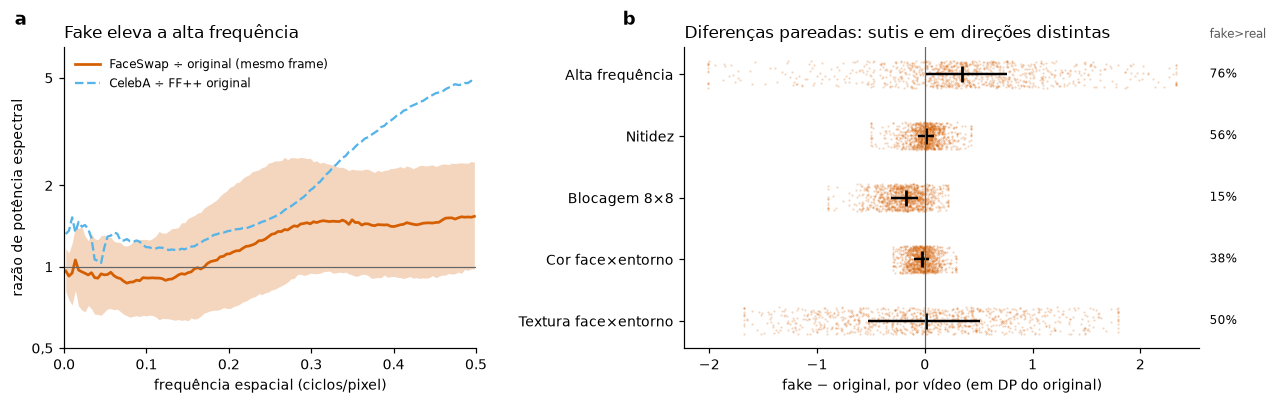

In [10]:
okf = man[(man.source == "FaceForensics++") & (man.detected == 1)]
pr = okf.pivot_table(index=["target_id", "frame_idx"], columns="group", values="row").dropna().astype(int)
L = np.log10(S[pr["ffpp_faceswap"].values] + 1e-9) - np.log10(S[pr["ffpp_real"].values] + 1e-9)
Lv = pd.DataFrame(L, index=pr.index.get_level_values(0)).groupby(level=0).mean().values
cel_rows = man[(man.group == "celeba_real") & (man.detected == 1)].row.values
ffr_rows = man[(man.group == "ffpp_real") & (man.detected == 1)].row.values
src = np.log10(np.nanmean(S[cel_rows], 0)) - np.log10(np.nanmean(S[ffr_rows], 0))
freq = (np.arange(128) + 0.5) / 128 * 0.5
q1, md_, q3 = np.percentile(Lv, [25, 50, 75], axis=0)
print(f"razão média acima de 0,25 ciclo/px — fake÷original: {10**md_[freq > 0.25].mean():.2f}×   CelebA÷FF++ original: {10**src[freq > 0.25].mean():.2f}×")

P2 = [("hf_ratio", "Alta frequência"), ("sharpness", "Nitidez"), ("blockiness", "Blocagem 8×8"), ("color_dist", "Cor face×entorno"), ("tex_logratio", "Textura face×entorno")]
pv2 = okf.pivot_table(index=["target_id", "frame_idx"], columns="group", values=[f for f, _ in P2])
st = []
for f, lab in P2:
    dv = (pv2[(f, "ffpp_faceswap")] - pv2[(f, "ffpp_real")]).dropna().groupby(level=0).mean() / pv2[(f, "ffpp_real")].std()
    st.append(dict(atributo=lab, videos=len(dv), mediana_DP=dv.median(), pct_fake_maior=(dv > 0).mean() * 100, p_wilcoxon=wilcoxon(dv).pvalue, _dv=dv))
stats3 = pd.DataFrame(st)
display(stats3.drop(columns="_dv").round(4))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1, 1.25], wspace=0.45))
ax = axs[0]
ax.fill_between(freq, 10**q1, 10**q3, color=COL["ffpp_faceswap"], alpha=0.25, lw=0); ax.plot(freq, 10**md_, color=COL["ffpp_faceswap"], lw=1.8, label="FaceSwap ÷ original (mesmo frame)")
ax.plot(freq, 10**src, color=COL["celeba_real"], ls="--", label="CelebA ÷ FF++ original"); ax.axhline(1, color="0.4", lw=0.8)
ax.set_yscale("log"); ax.set_xlim(0, 0.5); ax.set_ylim(0.6, 6.5); ax.set_yticks([0.5, 1, 2, 5], ["0,5", "1", "2", "5"]); ax.minorticks_off()
ax.set_xlabel("frequência espacial (ciclos/pixel)"); ax.set_ylabel("razão de potência espectral"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Fake eleva a alta frequência", loc="left"); letter(ax, "a")
ax = axs[1]; rng = np.random.default_rng(0)
for k, r in enumerate(st[::-1]):
    dv = r["_dv"]; lo, hi = np.percentile(dv, [1, 99]); dvc = dv.clip(lo, hi)
    ax.scatter(dvc, k + rng.uniform(-0.22, 0.22, len(dvc)), s=2, color=COL["ffpp_faceswap"], alpha=0.25, lw=0)
    a_, m_, b_ = np.percentile(dv, [25, 50, 75]); ax.hlines(k, a_, b_, color="k", lw=1.6); ax.plot(m_, k, "|", color="k", ms=11, mew=1.8)
    ax.text(1.02, k, f"{r['pct_fake_maior']:.0f}%", transform=ax.get_yaxis_transform(), va="center", fontsize=8)
ax.text(1.02, len(st) - 0.35, "fake>real", transform=ax.get_yaxis_transform(), va="center", fontsize=8, color="0.35")
ax.axvline(0, color="0.4", lw=0.8); ax.set_yticks(range(len(st)), [r["atributo"] for r in st[::-1]])
ax.set_xlabel("fake − original, por vídeo (em DP do original)"); ax.set_title("Diferenças pareadas: sutis e em direções distintas", loc="left"); letter(ax, "b")
fig.subplots_adjust(left=0.07, right=0.93, bottom=0.16)

**Interpretação:** o fake tem ≈1,45× mais energia acima de 0,25 ciclo/px que o seu original (valor maior em ~76% dos vídeos) e menos artefato de bloco em ~85% deles — sinais consistentes, mas pequenos perto da diferença de origem CelebA × FF++ (≈2,95×). A razão de textura pelo Laplaciano não diferencia as classes (~50%), então essa evidência precisará de uma medida mais específica no modelo final.

## 9. Modelo baseline — regressão logística

**Por que regressão logística?** É o classificador probabilístico mais simples: modela P(fake | x) = σ(w·x + b), tem coeficientes interpretáveis e produz probabilidades — o tipo de saída que a Rede Bayesiana do projeto vai consumir. Serve como ponto de partida mensurável para o modelo final.

**Três representações de entrada** (todas dos mesmos recortes 256×256):

1. **8 atributos manuais** da EDA (`sharpness`, `hf_ratio` e `face_px` em log);
2. **espectro radial** em 128 faixas (log) — o sinal da Visualização 3;
3. **embeddings ResNet-18** (512 dimensões) de uma rede pré-treinada no ImageNet e congelada (*linear probe*) — um classificador de pixels sem ajuste fino.

**Protocolo**

- Classe real = originais do FF++; classe fake = FaceSwap (c23). O CelebA fica **fora** do treino por causa do viés de origem.
- Splits oficiais **por vídeo** (nenhum vídeo aparece em dois splits), 10 frames por vídeo, classes balanceadas.
- Padronização (`StandardScaler`) ajustada só no treino, dentro de um `Pipeline`.
- Hiperparâmetro C ∈ {0,001; 0,01; 0,1; 1; 10; 100} escolhido pela AUC na **validação**; limiar fixo em 0,5.
- Variáveis de máscara **excluídas** (não existem na inferência).
- Métricas no **teste**: acurácia, precisão, recall, F1, AUC e Brier, por frame e por vídeo (média das probabilidades dos 10 frames).
- Intervalos de 95% por **bootstrap agrupado**: reamostramos vídeos-alvo (o original A e o fake A_B entram juntos), 2.000 vezes, porque frames do mesmo vídeo não são independentes.

In [11]:
import importlib, baselines as B
importlib.reload(B)
man_b, spec = B.load()                       # mesmo manifest + coluna 'cluster' para o bootstrap
okb = man_b[man_b.detected == 1].copy(); okb["row"] = okb.index
ffb = okb[okb.source == "FaceForensics++"]
tr, va, te = (ffb[ffb.split == s] for s in ["train", "val", "test"])
print({s: dict(frames=len(d), videos=d.video_id.nunique(), frac_fake=round(d.label.mean(), 3)) for s, d in zip(["treino", "val", "teste"], [tr, va, te])})

if RUN_CNN or not (D / "resnet18_feats.npz").exists():
    subprocess.run([sys.executable, "extract_cnn_features.py"], cwd=EDA, check=True)
R = np.load(D / "resnet18_feats.npz")["feats"]

REPS = {"LR + espectro radial": lambda d: B.spec_matrix(spec, d.row.values),
        "LR + 8 atributos manuais": B.hand_matrix,
        "LR + ResNet-18 congelada": lambda d: R[d.row.values]}
results, preds, models = [], {}, {}
for name, mk in REPS.items():
    val_auc, C_, m = B.fit(mk(tr), tr.label.values, mk(va), va.label.values)
    p = m.predict_proba(mk(te))[:, 1]; preds[name] = p; models[name] = m
    fr = B.metrics(te.label.values, p); v = B.video_level(te, p); vd = B.metrics(v.y.values, v.p.values)
    cf, cv = B.cluster_ci(te, p), B.cluster_ci(te, p, "video")
    results.append({"modelo": name, "C": C_, "AUC val": val_auc, "acurácia": fr["acc"], "precisão": fr["prec"], "recall": fr["rec"], "F1": fr["f1"],
                    "AUC frame": fr["auc"], "IC95 AUC frame": cf["auc_ci"], "Brier": fr["brier"], "acurácia vídeo": vd["acc"], "F1 vídeo": vd["f1"],
                    "AUC vídeo": vd["auc"], "IC95 AUC vídeo": cv["auc_ci"], "_vd": vd})
tab = pd.DataFrame(results).set_index("modelo")
display(tab.drop(columns="_vd").round(3))

{'treino': {'frames': 14398, 'videos': 1440, 'frac_fake': np.float64(0.5)}, 'val': {'frames': 2800, 'videos': 280, 'frac_fake': np.float64(0.5)}, 'teste': {'frames': 2800, 'videos': 280, 'frac_fake': np.float64(0.5)}}


,C,AUC val,acurácia,precisão,recall,F1,AUC frame,IC95 AUC frame,Brier,acurácia vídeo,F1 vídeo,AUC vídeo,IC95 AUC vídeo
modelo,,,,,,,,,,,,,
LR + espectro radial,0.001,0.794,0.725,0.711,0.756,0.733,0.769,"(0.731, 0.805)",0.196,0.732,0.737,0.792,"(0.75, 0.834)"
LR + 8 atributos manuais,0.100,0.692,0.655,0.641,0.703,0.671,0.705,"(0.665, 0.747)",0.218,0.668,0.683,0.726,"(0.681, 0.773)"
LR + ResNet-18 congelada,0.010,0.699,0.640,0.642,0.634,0.638,0.690,"(0.663, 0.721)",0.225,0.675,0.671,0.738,"(0.703, 0.779)"


**Coeficientes do modelo com atributos manuais** (variáveis padronizadas): o sinal e o tamanho indicam para que lado e com que força cada atributo empurra a previsão para "fake".

In [12]:
m = models["LR + 8 atributos manuais"]
pd.Series(m[-1].coef_[0], index=B.HAND).sort_values(key=abs, ascending=False).round(3).to_frame("coeficiente")

,coeficiente
hf_ratio,0.854
sharpness,-0.355
blockiness,-0.285
eye_dist_rel,-0.112
det_prob,0.022
brightness,0.017
face_px,0.009
saturation,0.004


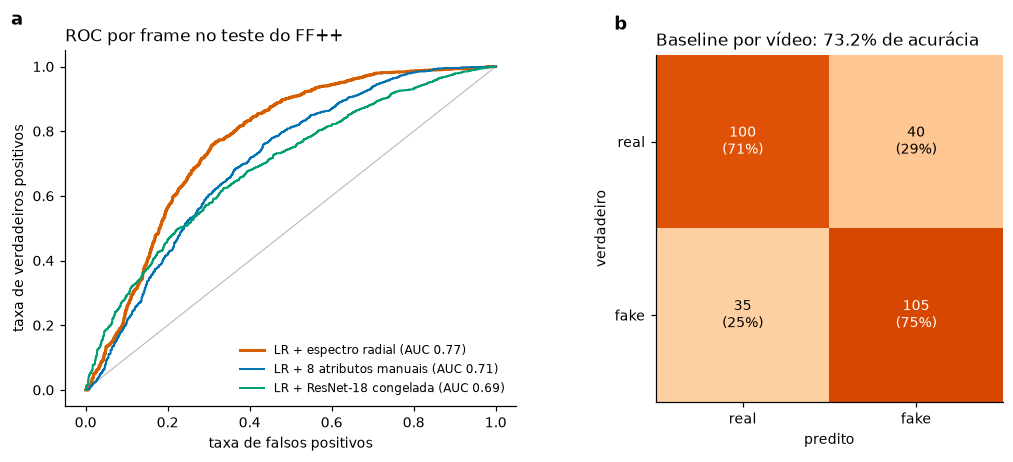

In [13]:
from sklearn.metrics import roc_curve, roc_auc_score
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1], wspace=0.35))
ax = axs[0]; ax.plot([0, 1], [0, 1], color="0.75", lw=0.8)
for (name, p), c, lw in zip(preds.items(), ["#D55E00", "#0072B2", "#009E73"], [2, 1.3, 1.3]):
    fpr, tpr, _ = roc_curve(te.label.values, p); ax.plot(fpr, tpr, color=c, lw=lw, label=f"{name} (AUC {roc_auc_score(te.label.values, p):.2f})")
ax.set_xlabel("taxa de falsos positivos"); ax.set_ylabel("taxa de verdadeiros positivos"); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("ROC por frame no teste do FF++", loc="left"); letter(ax, "a")
ax = axs[1]; vd = tab.loc["LR + espectro radial", "_vd"]; Mc = np.array([[vd["tn"], vd["fp"]], [vd["fn"], vd["tp"]]]).astype(int)
ax.imshow(Mc, cmap="Oranges", vmin=0, vmax=140)
for i in range(2):
    for j in range(2): ax.text(j, i, f"{Mc[i, j]}\n({Mc[i, j]/140*100:.0f}%)", ha="center", va="center", color="white" if Mc[i, j] > 80 else "black")
ax.set_xticks([0, 1], ["real", "fake"]); ax.set_yticks([0, 1], ["real", "fake"]); ax.set_xlabel("predito"); ax.set_ylabel("verdadeiro")
ax.set_title(f"Baseline por vídeo: {vd['acc']*100:.1f}% de acurácia", loc="left"); letter(ax, "b")

**Leitura:** o baseline adotado é a **regressão logística sobre o espectro radial** (melhor AUC na validação). Ele detecta a manipulação acima do acaso com um único sinal simples (AUC ≈ 0,77 por frame e ≈ 0,79 por vídeo), mas erra cerca de um em cada quatro vídeos. A ResNet-18 congelada é a mais fraca: os traços de manipulação não aparecem em features genéricas do ImageNet, e o classificador de pixels final precisará de ajuste fino.

## 10. Controle do viés de origem

Treinamos a **mesma** regressão (atributos manuais) usando o CelebA como classe real e o FaceSwap como fake, e avaliamos em dois testes: (i) CelebA × FaceSwap, a mesma "distribuição" do treino; (ii) FF++ original × FaceSwap, onde a origem é a mesma para as duas classes. Se o modelo tivesse aprendido a manipulação, deveria funcionar nos dois.

In [14]:
cel = okb[okb.group == "celeba_real"]; fs = ffb[ffb.group == "ffpp_faceswap"]
mk_split = lambda s: pd.concat([cel[cel.split == s], fs[fs.split == s]])
trS, vaS, teS = mk_split("train"), mk_split("val"), mk_split("test")
out = {}
for name, mk in [("8 atributos manuais", B.hand_matrix), ("ResNet-18 congelada", lambda d: R[d.row.values])]:
    _, C_, mS = B.fit(mk(trS), trS.label.values, mk(vaS), vaS.label.values)
    a = B.metrics(teS.label.values, mS.predict_proba(mk(teS))[:, 1])
    pff = mS.predict_proba(mk(te))[:, 1]; b = B.metrics(te.label.values, pff)
    out[name] = {"acurácia CelebA×fake": a["acc"], "AUC CelebA×fake": a["auc"], "acurácia FF++": b["acc"], "AUC FF++": b["auc"],
                 "% originais FF++ chamados de fake": (pff[te.label.values == 0] >= 0.5).mean() * 100}
pd.DataFrame(out).T.round(3)

,acurácia CelebA×fake,AUC CelebA×fake,acurácia FF++,AUC FF++,% originais FF++ chamados de fake
8 atributos manuais,0.968,0.991,0.503,0.514,94.143
ResNet-18 congelada,0.961,0.992,0.505,0.518,93.857


**Leitura:** treinado com CelebA como real, o modelo parece excelente (≈97% de acurácia, AUC ≈ 0,99), mas no FF++ cai para AUC ≈ 0,51 (acaso) e chama ≈94% dos rostos **reais** do FF++ de fake. Ele aprendeu a origem da imagem, não a manipulação. Por isso, todas as comparações do projeto usam reais e fakes da **mesma origem**.

## 11. Conclusões

1. **Dados íntegros:** sem faltantes nas anotações, sem falhas de decodificação, detecção acima de 99,8%; splits oficiais do FF++ sem vazamento entre vídeos.
2. **Unidade de análise = vídeo:** a classe fake tem 1.000 amostras independentes; amostragem, divisão e intervalos de confiança respeitam o vídeo.
3. **Viés de origem confirmado:** compressão e resolução separam CelebA dos fakes quase perfeitamente; o CelebA não deve ser a classe real do treino.
4. **Sinais de manipulação existem, mas são fracos isoladamente** (AUC entre 0,69 e 0,77) e apontam em direções distintas — o que justifica combiná-los numa Rede Bayesiana.
5. **Baseline a superar:** regressão logística sobre o espectro radial, AUC de 0,77 (frame) e 0,79 (vídeo) no teste do FF++ c23.

**Próximos passos (Marco 2):** ajuste fino e calibração de uma CNN (EfficientNet-B0/XceptionNet), novas evidências (segmentação facial, resíduo de ruído, compressão c40), construção e avaliação da Rede Bayesiana, e teste cross-dataset no Celeb-DF.